# Hedging the factor exposures of the strategies

[`03_strategy_decomposition`](03_strategy_decomposition.ipynb) shows how much of the risk of each strategy comes from each factor. This notebook uses that to hedge it: each month the strategy is held and the factors are sold in proportion to its exposures, so that what is left is the part of the return the factors do not explain.

- **Betas without hindsight.** At the start of each month, the betas of the strategy come from a regression of its monthly returns in excess of the SELIC rate on the seven factors, over the previous 36 months only. In the month that follows, the hedge sells $\beta_k$ of each factor.
- **What is sold.** The market factor is the Ibovespa in excess of the SELIC rate, which an index future delivers. The other six are long-short portfolios that cost nothing to hold, before costs. So the hedged portfolio earns the SELIC rate plus $r - r_f - \sum_k \beta_k f_k$.
- **Hedges.** Four versions are compared, from the simplest to the full one:
  - only the index, with the beta of a regression on the market alone;
  - the orthogonal market factor;
  - the orthogonal market and size factors;
  - all seven factors.

  With orthogonal factors, each step removes one share of the decomposition. Hedging all seven gives the same result with original or orthogonal factors.

The first 36 months, February 2010 to January 2013, only feed the first estimate, so the hedged returns run from February 2013 to June 2026 (from February 2014 for Quality, which starts a year later). All returns are before transaction and borrowing costs.

In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import statsmodels.api as sm
from pathlib import Path

from orthofactors.data import (load_brazil_factors, load_brazil_strategies, to_monthly, BRAZIL_FACTORS,
                               BRAZIL_STRATEGIES, MONTHLY_SAMPLE)
from orthofactors.orthogonalization import orthogonalize_swl
from orthofactors.decomposition import decompose
from orthofactors.plotting import set_style, factor_colors, CATEGORICAL

set_style()
Path('results').mkdir(exist_ok = True)
colors = factor_colors(BRAZIL_FACTORS)

In [2]:
daily = load_brazil_factors()
factors = to_monthly(daily[BRAZIL_FACTORS]).loc[MONTHLY_SAMPLE]
selic = to_monthly(daily[['Risk_Free']]).loc[MONTHLY_SAMPLE]['Risk_Free']
strategies = to_monthly(load_brazil_strategies()).loc[MONTHLY_SAMPLE]

## The hedge

In [3]:
def hedge(returns, factor_returns, window = 36):
    # Monthly excess returns of the strategy under each hedge, and the hedge ratios used in each month.
    # The betas of month t come only from months t - window to t - 1.
    data = pd.concat([returns.rename('asset'), factor_returns], axis = 1).dropna()
    y, F = data['asset'], data[factor_returns.columns]
    hedged, ratios = {}, {}
    for i in range(window, len(data)):
        y_past, F_past = y.iloc[i - window:i], F.iloc[i - window:i]
        beta = sm.OLS(y_past, sm.add_constant(F_past)).fit().params[F.columns]
        capm = sm.OLS(y_past, sm.add_constant(F_past['Mkt_RF'])).fit().params['Mkt_RF']

        # Orthogonal factors of the window: F_ortho = F S, with betas Psi beta
        _, S, Psi = orthogonalize_swl(F_past, return_matrices = True)
        beta_ortho = pd.Series(Psi.values @ beta.values, index = F.columns)
        f_ortho = pd.Series(F.iloc[i].values @ S.values, index = F.columns)
        assert abs(beta_ortho @ f_ortho - beta @ F.iloc[i]) < 1e-12

        month = data.index[i]
        hedged[month] = {'Unhedged': y.iloc[i],
                         'Index only': y.iloc[i] - capm * F['Mkt_RF'].iloc[i],
                         'Market (orthogonal)': y.iloc[i] - beta_ortho['Mkt_RF'] * f_ortho['Mkt_RF'],
                         'Market and size (orthogonal)': y.iloc[i] - beta_ortho[['Mkt_RF', 'SMB']] @ f_ortho[['Mkt_RF', 'SMB']],
                         'All seven factors': y.iloc[i] - beta @ F.iloc[i]}
        ratios[month] = pd.concat([pd.Series({'Index only': capm}), beta])
    return pd.DataFrame(hedged).T, pd.DataFrame(ratios).T

def performance(excess):
    # Total return of the hedged portfolio, which earns the SELIC rate plus the hedged excess return
    wealth = (1 + excess + selic.loc[excess.index]).cumprod()
    return pd.Series({'Total return a year': wealth.iloc[-1] ** (12 / len(excess)) - 1,
                      'Excess return a year': excess.mean() * 12,
                      'Volatility': excess.std() * np.sqrt(12),
                      'Sharpe ratio': excess.mean() / excess.std() * np.sqrt(12),
                      'Maximum drawdown': (wealth / wealth.cummax() - 1).min(),
                      'Correlation with Mkt_RF': excess.corr(factors['Mkt_RF'].loc[excess.index])})

table_format = {'Total return a year': '{:.1%}', 'Excess return a year': '{:.1%}', 'Volatility': '{:.1%}',
                'Sharpe ratio': '{:.2f}', 'Maximum drawdown': '{:.1%}', 'Correlation with Mkt_RF': '{:.2f}'}

results = {s: hedge(strategies[s], factors) for s in BRAZIL_STRATEGIES}
combination, combination_ratios = results['Combination']
print(f"Combination: hedged months from {combination.index[0]:%Y-%m} to {combination.index[-1]:%Y-%m}; "
      f"SELIC in the same months: {(1 + selic.loc[combination.index]).prod() ** (12 / len(combination)) - 1:.1%} a year; "
      f"mean of Mkt_RF: {factors['Mkt_RF'].loc[combination.index].mean() * 12:.1%} a year")
combination.apply(performance).T.style.format(table_format)

Combination: hedged months from 2013-02 to 2026-06; SELIC in the same months: 9.8% a year; mean of Mkt_RF: 0.8% a year


,Total return a year,Excess return a year,Volatility,Sharpe ratio,Maximum drawdown,Correlation with Mkt_RF
Unhedged,13.0%,4.9%,19.5%,0.25,-36.3%,0.87
Index only,13.4%,3.7%,10.0%,0.37,-16.9%,0.13
Market (orthogonal),11.0%,1.7%,10.9%,0.15,-16.4%,0.09
Market and size (orthogonal),12.1%,2.5%,9.3%,0.27,-16.6%,-0.06
All seven factors,10.1%,0.6%,8.3%,0.07,-20.0%,0.04


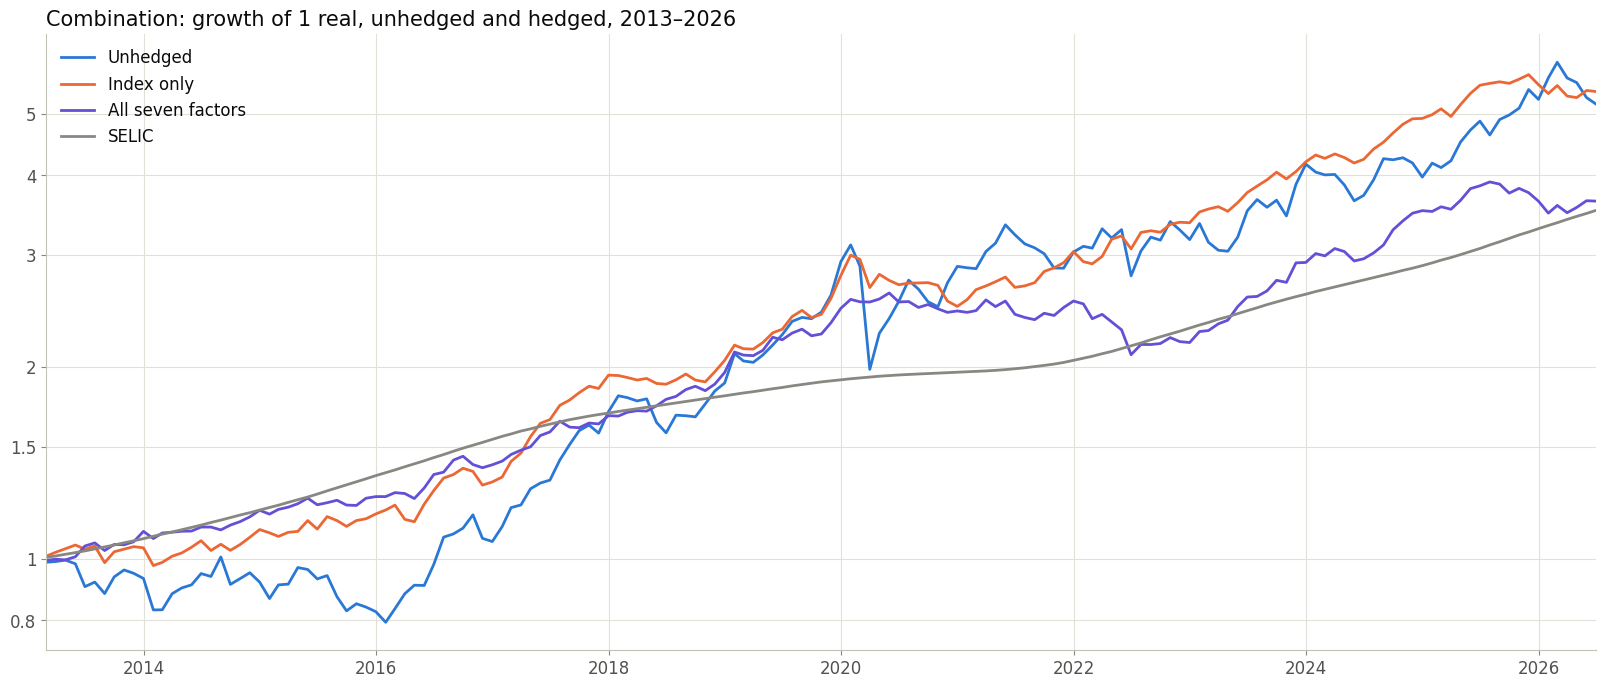

In [4]:
# Growth of 1 real, total return
wealth = (1 + combination[['Unhedged', 'Index only', 'All seven factors']].add(selic.loc[combination.index], axis = 0)).cumprod()
wealth['SELIC'] = (1 + selic.loc[combination.index]).cumprod()

fig, ax = plt.subplots()
for name, color in zip(wealth.columns, [CATEGORICAL[0], CATEGORICAL[1], CATEGORICAL[6], '#898781']):
    ax.plot(wealth.index, wealth[name], color = color, label = name, linewidth = 2)
ax.set_yscale('log')
ax.set_yticks([0.8, 1, 1.5, 2, 3, 4, 5])
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f'{y:g}'))
ax.yaxis.set_minor_locator(ticker.NullLocator())
ax.margins(x = 0)
ax.set_title('Combination: growth of 1 real, unhedged and hedged, 2013–2026')
ax.legend(loc = 'upper left')
plt.show()

Selling only the index, at a beta of 0.75 on average, cuts the volatility of the Combination from 19.5% to 10.0% and its maximum drawdown from −36% to −17%, and its correlation with the market falls from 0.87 to 0.13. The market factor earned only 0.8% a year over the SELIC rate in these months, so the hedge cost little: the excess return falls from 4.9% to 3.7% a year, but with half the volatility the compound total return even rises, from 13.0% to 13.4% a year, and the Sharpe ratio goes from 0.25 to 0.37.

Hedging all seven factors leaves 10.1% a year, only 0.3 point above the SELIC rate (an excess return of 0.6% a year), with a volatility of 8.3%. So almost all the excess return of the Combination came from its exposures to the factors, and the alpha of 0.34% a month measured over the whole sample in [`03_strategy_decomposition`](03_strategy_decomposition.ipynb) does not survive when the betas come only from past data. Hedging the orthogonal market alone does worse than hedging the index: the orthogonal market mixes several factors (see [`02_brazil_factors`](02_brazil_factors.ipynb)) and removes only the market's share of the variance, while the regression on the market alone also catches the risk the other factors share with it.

## What the hedge sells

In [5]:
# Average hedge ratio of each strategy: how much of each factor is sold per real in the strategy
pd.DataFrame({s: results[s][1].mean() for s in BRAZIL_STRATEGIES}).T.round(2)

,Index only,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB
Combination,0.75,0.84,0.34,0.05,0.20,0.01,0.17,0.34
Magic Formula,0.68,0.79,0.42,0.01,0.14,-0.10,0.18,0.43
LowVol Momentum,0.65,0.83,0.28,0.01,0.07,0.13,0.37,0.36
Quality,0.95,0.90,0.33,0.13,0.38,-0.01,-0.06,0.22


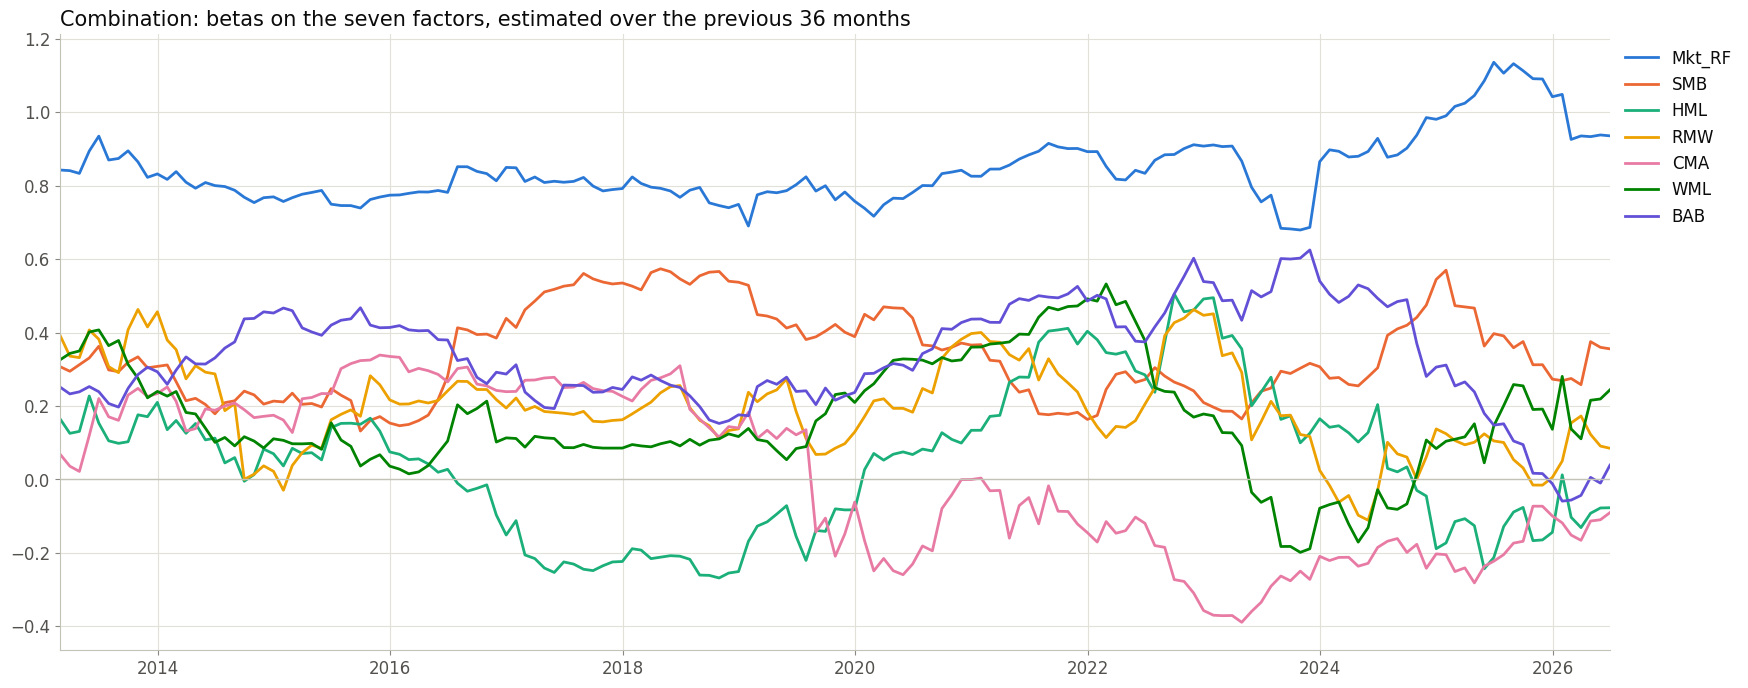

In [6]:
fig, ax = plt.subplots()
for factor in BRAZIL_FACTORS:
    ax.plot(combination_ratios.index, combination_ratios[factor], color = colors[factor], label = factor, linewidth = 2)
ax.axhline(0, color = '#c3c2b7', linewidth = 1)
ax.margins(x = 0)
ax.set_title('Combination: betas on the seven factors, estimated over the previous 36 months')
ax.legend(loc = 'upper left', bbox_to_anchor = (1.0, 1.0))
plt.show()

In [7]:
# Range of the hedge ratios of the Combination over the hedged months
combination_ratios.agg(['min', 'mean', 'max']).round(2)

,Index only,Mkt_RF,SMB,HML,RMW,CMA,WML,BAB
min,0.50,0.68,0.13,-0.27,-0.11,-0.39,-0.20,-0.06
mean,0.75,0.84,0.34,0.05,0.20,0.01,0.17,0.34
max,1.09,1.14,0.57,0.51,0.46,0.34,0.53,0.63


On average, the index hedge of the Combination sells 0.75 of the Ibovespa per real. With all seven factors, it sells 0.84 of the market, 0.34 of size and 0.34 of BAB, plus smaller amounts of profitability (0.20) and momentum (0.17). The betas move a lot from one window to the next: the market beta goes from 0.68 to 1.14, and those of value, profitability, investment, momentum and BAB change sign over the period. Each change is a trade in the hedge, and the estimation noise becomes noise in the hedged return.

## The decomposition as a risk budget

Hedging an orthogonal factor removes its share of the variance. The table compares the share of the variance removed by each hedge in the hedged months, out of sample, with the decomposed $R^2$ of [`03_strategy_decomposition`](03_strategy_decomposition.ipynb), measured over the whole sample.

In [8]:
budget = {}
for s, (hedged, _) in results.items():
    removed = 1 - hedged.var() / hedged['Unhedged'].var()
    _, dr2 = decompose(strategies[s], factors)
    budget[s] = {('Market', 'Removed, out of sample'): removed['Market (orthogonal)'],
                 ('Market', 'Decomposed R², in sample'): dr2['Mkt_RF'],
                 ('Market and size', 'Removed, out of sample'): removed['Market and size (orthogonal)'],
                 ('Market and size', 'Decomposed R², in sample'): dr2[['Mkt_RF', 'SMB']].sum(),
                 ('All seven', 'Removed, out of sample'): removed['All seven factors'],
                 ('All seven', 'Decomposed R², in sample'): dr2.sum()}
pd.DataFrame(budget).T.style.format('{:.1%}')

The decomposition works as a risk budget out of sample. Hedging the orthogonal market removes 69% of the variance of the Combination in the hedged months, against a decomposed R² of 70% over the whole sample; adding size, 78% against 82%; and all seven factors, 82% against 86%. The hedges remove a little less than the decomposition predicts, because the betas of each month are estimated with error, and the gap is largest for the Magic Formula and Quality, about 8 points with all seven factors.

## The three sleeves

In [9]:
sleeves = pd.concat({s: results[s][0].apply(performance).T.loc[['Unhedged', 'Index only', 'All seven factors']]
                     for s in BRAZIL_STRATEGIES[1:]})
sleeves.style.format(table_format)

The sleeves tell the same story. The index hedge cuts their volatility to 12% to 14% and their maximum drawdown to between 14% and 26%, with about the same total return, and it raises the Sharpe ratio of LowVol Momentum from 0.30 to 0.37 and of the Magic Formula from 0.23 to 0.25, leaving that of Quality at 0.27. Hedging all seven factors leaves less than 2 points a year of excess return for each sleeve. For Quality, whose hedge removes the least of its variance, it even leaves a deeper drawdown than no hedge, −40% against −39%.

## Robustness: 60-month windows

The same hedges with betas from the previous 60 months, so the hedged months start in February 2015.

In [10]:
combination_60, _ = hedge(strategies['Combination'], factors, window = 60)
combination_60.apply(performance).T.style.format(table_format)

,Total return a year,Excess return a year,Volatility,Sharpe ratio,Maximum drawdown,Correlation with Mkt_RF
Unhedged,17.0%,8.4%,19.9%,0.42,-36.3%,0.87
Index only,15.3%,5.3%,10.1%,0.53,-14.3%,0.19
Market (orthogonal),14.7%,4.9%,10.4%,0.47,-13.2%,0.13
Market and size (orthogonal),15.4%,5.3%,8.7%,0.61,-13.3%,-0.10
All seven factors,12.5%,2.8%,8.5%,0.33,-12.0%,0.04


With 60-month windows, from February 2015, every version does better, because the period leaves out the weak years of 2013 and 2014: the index hedge has a Sharpe ratio of 0.53 against 0.42 unhedged, and hedging all seven factors leaves 2.8% a year of excess return, with a volatility of 8.5% and a maximum drawdown of −12%. In this period the index hedge costs return, 15.3% a year against 17.0%, since the market did better than the SELIC rate after 2015.

The conclusions hold in both periods: the index hedge halves the volatility and the drawdown and raises the Sharpe ratio, while what is left after hedging all seven factors is small and depends on the period. These results are before costs. The index can be sold cheaply with futures, but the factor hedges mean shorting baskets of stocks, and borrowing stocks in Brazil is expensive, so the full hedge would earn less than shown here.

In [11]:
pd.concat({s: results[s][0].apply(performance).T for s in BRAZIL_STRATEGIES}).round(4).to_csv('results/hedge_performance.csv')
combination.round(6).to_csv('results/hedge_combination_monthly.csv')